# Question 2 — Segmentation des données simulées `sequencesimu`

L’objectif est de segmenter une séquence de **160 observations bi-dimensionnelles** à l’aide de l’algorithme de Fisher.

Contrairement aux données `aiguillage`, **le nombre de classes n’est pas donné** et **aucune partition de référence n’est fournie**. Nous procédons donc en trois temps :
- choisir le nombre de segments **K** par la **méthode du coude** appliquée au critère d’inertie **C** de Fisher ;
- interpréter la segmentation obtenue ;
- la comparer aux partitions calculées par **K-means** et par la **classification ascendante hiérarchique (CAH) de Ward**.

Comme pour `aiguillage`, la comparaison met en évidence l’effet de la **contrainte d’ordre** : Fisher construit des segments successifs, alors que K-means et Ward regroupent les observations sans tenir compte de leur position dans la séquence.

## 1. Imports

Nous importons les fonctions de classification **Fisher, K-means et Ward**, ainsi que les critères d’évaluation définis dans `utils.py` : **inertie, ARI et silhouette**.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from utils import (
    clustfisher, clustkmeans, clustward,
    inertie, compare_partitions, silhouette,
)

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
couleurs = ["#2563eb", "#d97706", "#059669", "#9333ea", "#dc2626", "#0891b2"]

## 2. Chargement et description des données

Le fichier `sequencesimu.txt` contient un en-tête (`var1`, `var2`) puis **160 lignes de deux variables**, séparées par des espaces. Il n’y a pas de colonne de classes : toutes les colonnes constituent la matrice `X`.

Nous conservons **l’ordre initial des lignes**, indispensable à la segmentation de Fisher. Les deux variables étant sur des échelles comparables, nous travaillons sur les **données brutes, sans standardisation**.

In [2]:
chemin = Path("data/sequencesimu.txt")
df = pd.read_csv(chemin, sep=r"\s+")
X = df.to_numpy(dtype=float)
n, p = X.shape

assert X.shape == (160, 2), "La dimension du fichier est inattendue."
assert np.isfinite(X).all(), "Le fichier contient des valeurs manquantes ou infinies."

print(f"Nombre d'observations : {n}")
print(f"Nombre de variables : {p}")
display(df.describe().T[["mean", "std", "min", "max"]])

Nombre d'observations : 160
Nombre de variables : 2


,mean,std,min,max
var1,0.6926,1.8319,-2.1853,5.8675
var2,0.5614,1.4848,-2.2199,4.2865


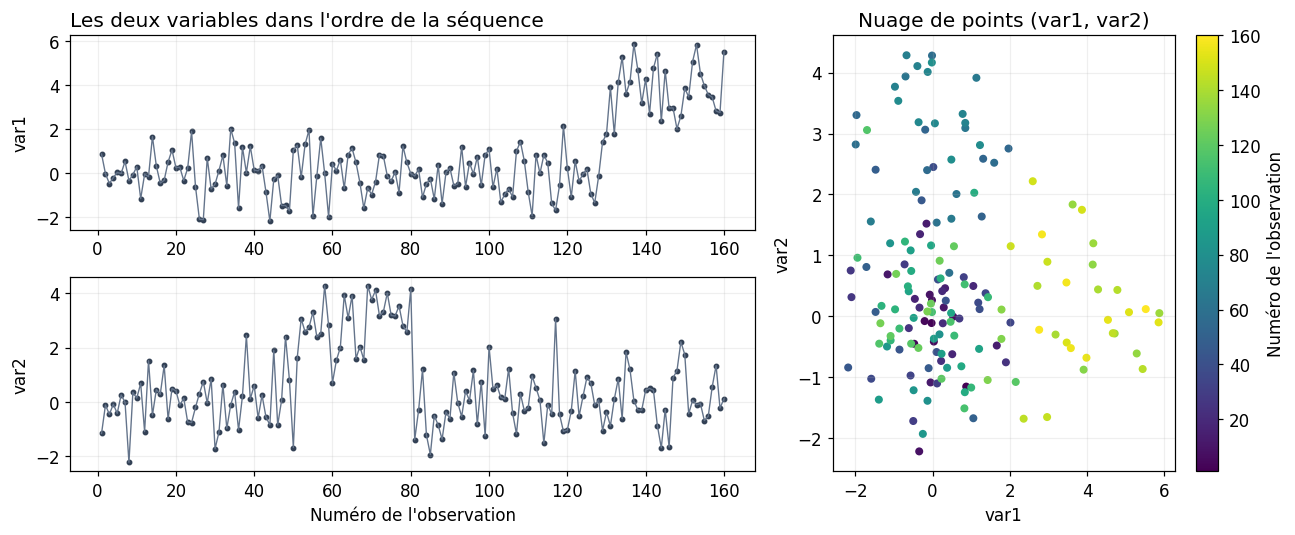

In [3]:
observations = np.arange(1, n + 1)

fig = plt.figure(figsize=(12, 5))
grille = fig.add_gridspec(2, 2, width_ratios=[1.6, 1])
ax1 = fig.add_subplot(grille[0, 0])
ax2 = fig.add_subplot(grille[1, 0], sharex=ax1)
ax3 = fig.add_subplot(grille[:, 1])

for ax, j in zip([ax1, ax2], range(p)):
    ax.plot(observations, X[:, j], color="#64748b", linewidth=0.9)
    ax.scatter(observations, X[:, j], s=8, color="#334155")
    ax.set_ylabel(df.columns[j])
    ax.grid(alpha=0.2)
ax1.set_title("Les deux variables dans l'ordre de la séquence", loc="left")
ax2.set_xlabel("Numéro de l'observation")

nuage = ax3.scatter(X[:, 0], X[:, 1], c=observations, cmap="viridis", s=18)
fig.colorbar(nuage, ax=ax3, label="Numéro de l'observation")
ax3.set(title="Nuage de points (var1, var2)", xlabel="var1", ylabel="var2")
ax3.grid(alpha=0.2)

fig.tight_layout()
plt.show()

<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des données</strong>

  <p>
    La séquence compte <strong>160 observations</strong> et <strong>deux variables</strong>,
    sans vraies classes : les partitions seront comparées entre elles.
  </p>

  <p style="margin-bottom: 0;">
    On repère des <strong>changements de niveau</strong> : <code>var2</code> monte vers 3
    entre les observations 50 et 80, <code>var1</code> monte vers 4 en fin de séquence.
    Le nuage montre trois zones, (0, 0), (0, 3) et (4, 0) ; la zone (0, 0)
    est visitée au début <em>et</em> au milieu de la séquence.
  </p>

</div>

## 3. Choix du nombre de segments : méthode du coude

Pour chaque valeur de **K entre 1 et 15**, nous appliquons Fisher et relevons le critère optimal **C(K)**, c’est-à-dire l’inertie intra-segments minimale parmi les partitions en K segments contigus.

C(K) décroît toujours quand K augmente : ajouter un segment ne peut pas dégrader l’optimum. Nous cherchons donc le **coude** de la courbe, c’est-à-dire la valeur de K au-delà de laquelle **ajouter un segment ne réduit plus que faiblement le critère**. Nous examinons la courbe et le **gain** apporté par chaque segment supplémentaire, C(K−1) − C(K).

In [4]:
K_max = 15
valeurs_K = np.arange(1, K_max + 1)
resultats_fisher = {K: clustfisher(X, int(K)) for K in valeurs_K}
C = np.array([resultats_fisher[K][2] for K in valeurs_K])

gains = np.r_[np.nan, -np.diff(C)]
coude = pd.DataFrame({
    "C(K)": C,
    "Gain C(K-1) - C(K)": gains,
    "Gain relatif (% de C(K-1))": np.r_[np.nan, 100 * gains[1:] / C[:-1]],
    "Ruptures de Fisher": [str(resultats_fisher[K][0].tolist()) for K in valeurs_K],
}, index=pd.Index(valeurs_K, name="K"))
display(coude.head(8))

,C(K),Gain C(K-1) - C(K),Gain relatif (% de C(K-1)),Ruptures de Fisher
K,,,,
1,884.1367,NaN,NaN,[]
2,503.5847,380.5520,43.0422,[131]
3,462.0128,41.5719,8.2552,"[81, 131]"
4,300.5963,161.4165,34.9377,"[51, 81, 131]"
5,292.3740,8.2223,2.7353,"[51, 81, 129, 133]"
6,285.4685,6.9055,2.3619,"[51, 69, 81, 129, 133]"
7,277.5583,7.9102,2.7710,"[44, 50, 51, 81, 129, 133]"
8,270.6528,6.9055,2.4879,"[44, 50, 51, 69, 81, 129, 133]"


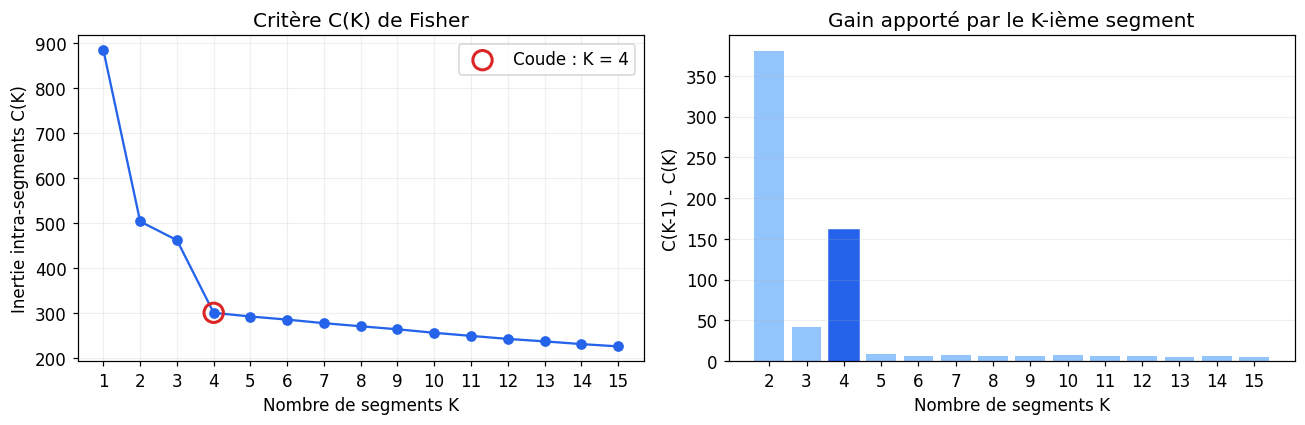

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(valeurs_K, C, marker="o", color="#2563eb")
axes[0].scatter([4], [C[3]], s=160, facecolors="none", edgecolors="#dc2626",
                linewidths=2, zorder=3, label="Coude : K = 4")
axes[0].set(title="Critère C(K) de Fisher", xlabel="Nombre de segments K",
            ylabel="Inertie intra-segments C(K)", xticks=valeurs_K)
axes[0].legend()
axes[0].grid(alpha=0.2)

barres = axes[1].bar(valeurs_K[1:], gains[1:], color="#93c5fd")
barres[2].set_color("#2563eb")    # passage de K = 3 à K = 4
axes[1].set(title="Gain apporté par le K-ième segment",
            xlabel="Nombre de segments K", ylabel="C(K-1) - C(K)",
            xticks=valeurs_K[1:])
axes[1].grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()

<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation de la méthode du coude</strong>

  <p>
    C(K) chute fortement jusqu’à <strong>K = 4</strong> (gain d’environ 161 entre 3 et 4),
    puis chaque segment supplémentaire ne fait plus gagner environ 5  à 8 unités.
  </p>

  <p style="margin-bottom: 0;">
    Le coude est donc en <strong>K = 4</strong> : au-delà, les faibles gains après K=4 suggèrent que les segments supplémentaires décrivent surtout des variations résiduelles.
  </p>

</div>

## 4. Segmentation de Fisher avec K = 4

Nous reprenons la solution de Fisher pour K = 4 et décrivons chaque segment par ses bornes, son effectif, sa moyenne et son écart-type sur chaque variable.

In [6]:
K = 4
t, cluster_fisher, C_fisher = resultats_fisher[K]
bornes = np.r_[1, t, n + 1]

print("Débuts des nouveaux segments de Fisher :", t)
print(f"Critère C(4) : {C_fisher:,.2f}")

lignes = []
for k in range(K):
    segment = X[bornes[k] - 1:bornes[k + 1] - 1]
    lignes.append({
        "Segment": k + 1,
        "Première observation": bornes[k],
        "Dernière observation": bornes[k + 1] - 1,
        "Effectif": len(segment),
        "Moyenne var1": segment[:, 0].mean(),
        "Moyenne var2": segment[:, 1].mean(),
        "Écart-type var1": segment[:, 0].std(),
        "Écart-type var2": segment[:, 1].std(),
    })
segments = pd.DataFrame(lignes).set_index("Segment")
display(segments)

Débuts des nouveaux segments de Fisher : [ 51  81 131]
Critère C(4) : 300.60


,Première observation,Dernière observation,Effectif,Moyenne var1,Moyenne var2,Écart-type var1,Écart-type var2
Segment,,,,,,,
1,1,50,50,-0.0606,-0.0003,0.9815,0.9464
2,51,80,30,0.0886,2.9300,0.9830,0.9294
3,81,130,50,-0.1032,-0.0596,0.9335,0.9535
4,131,160,30,3.8783,0.1643,1.1168,0.9363


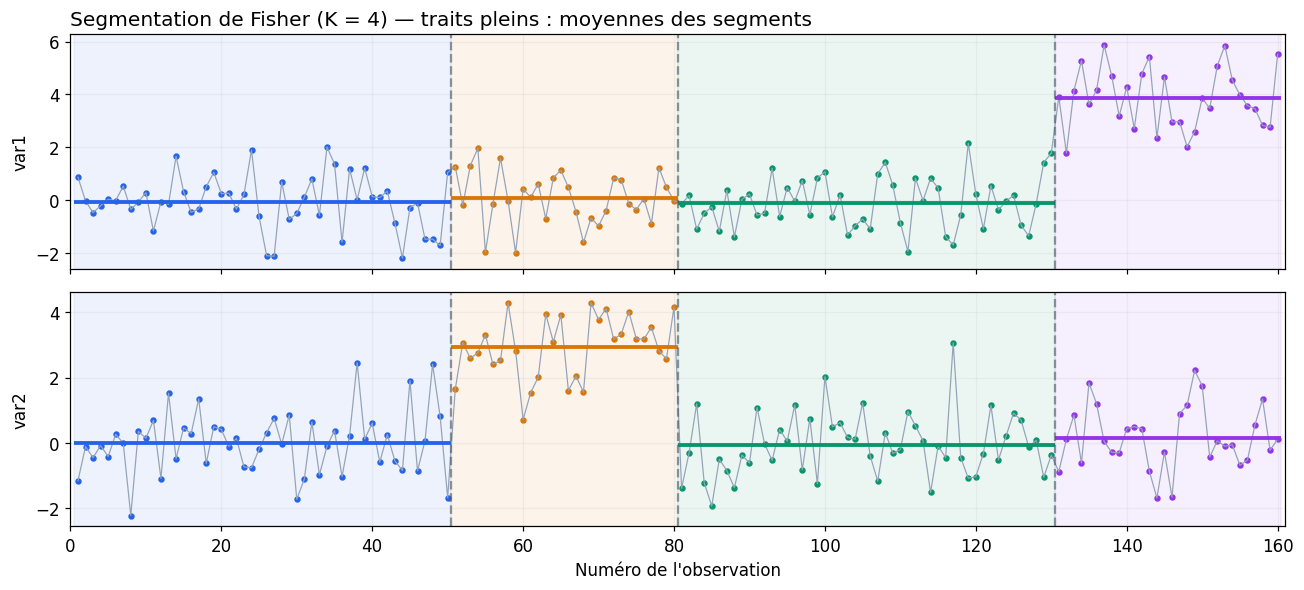

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)

for ax, j in zip(axes, range(p)):
    ax.plot(observations, X[:, j], color="#94a3b8", linewidth=0.8)
    for k in range(K):
        debut, fin = bornes[k], bornes[k + 1] - 1
        ax.axvspan(debut - 0.5, fin + 0.5, color=couleurs[k], alpha=0.08)
        ax.scatter(observations[debut - 1:fin], X[debut - 1:fin, j],
                   s=10, color=couleurs[k])
        ax.hlines(X[debut - 1:fin, j].mean(), debut - 0.5, fin + 0.5,
                  color=couleurs[k], linewidth=2.5)
    for rupture in t:
        ax.axvline(rupture - 0.5, color="#475569", linestyle="--", alpha=0.6)
    ax.set_ylabel(df.columns[j])
    ax.grid(alpha=0.15)

axes[0].set_title("Segmentation de Fisher (K = 4) — traits pleins : moyennes des segments",
                  loc="left")
axes[1].set_xlabel("Numéro de l'observation")
axes[1].set_xlim(0, n + 1)
fig.tight_layout()
plt.show()

<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation de la segmentation de Fisher</strong>

  <p>
    Fisher découpe la séquence en <strong>1–50, 51–80, 81–130 et 131–160</strong>,
    de moyennes proches de (0, 0), (0, 3), (0, 0) et (4, 0), avec un écart-type
    voisin de 1 partout : seule la moyenne change.
  </p>

  <p style="margin-bottom: 0;">
    Les <strong>segments 1 et 3 ont la même moyenne</strong> : Fisher les sépare
    uniquement parce qu’ils ne sont pas contigus.
  </p>

</div>

## 5. Comparaison avec K-means et la CAH de Ward

Nous appliquons les deux méthodes étudiées en cours, sans contrainte d’ordre, avec le même nombre de classes **K = 4** :

- **K-means** regroupe les observations autour de quatre centres. Nous utilisons dix initialisations et conservons la solution de plus faible inertie ; une graine fixe permet de reproduire le calcul.
- **La CAH de Ward** fusionne progressivement les groupes en limitant l’augmentation de l’inertie, puis la hiérarchie est coupée en quatre classes.

Aucune vraie partition n’étant disponible, nous comparons les méthodes avec :

- **Inertie** : plus elle est faible, plus les groupes sont compacts ;
- **Silhouette** : plus elle est proche de 1, mieux les groupes sont séparés ;
- **Nombre de changements de classe** le long de la séquence : 3 pour une segmentation en 4 blocs contigus ;
- **ARI** entre partitions : 1 si deux partitions forment exactement les mêmes groupes.

In [8]:
cluster_kmeans, C_kmeans = clustkmeans(X, K)
cluster_ward, C_ward = clustward(X, K)

partitions = {
    "Fisher": cluster_fisher,
    "K-means": cluster_kmeans,
    "Ward": cluster_ward,
}
criteres = {"Fisher": C_fisher, "K-means": C_kmeans, "Ward": C_ward}

lignes = []
for nom, cluster in partitions.items():
    lignes.append({
        "Méthode": nom,
        "Inertie": criteres[nom],
        "Silhouette": silhouette(X, cluster),
        "Changements de classe": int(np.sum(cluster[1:] != cluster[:-1])),
        "ARI avec Fisher": compare_partitions(cluster_fisher, cluster),
    })

resultats = pd.DataFrame(lignes).set_index("Méthode")
display(resultats)

,Inertie,Silhouette,Changements de classe,ARI avec Fisher
Méthode,,,,
Fisher,300.5963,0.1549,3,1.0000
K-means,202.8898,0.3717,75,0.3896
Ward,246.5757,0.3735,45,0.3919


<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des critères</strong>

  <p>
    <strong>K-means et Ward ont une inertie plus faible et une meilleure silhouette</strong>
    que Fisher, car ils ne sont pas contraints à des segments contigus.
    La faible silhouette de Fisher (≈ 0,15) vient des segments 1 et 3,
    qui se superposent dans le plan.
  </p>

  <p style="margin-bottom: 0;">
    En revanche, K-means et Ward changent de classe des dizaines de fois
    le long de la séquence (contre 3 pour Fisher) : leurs groupes ne sont
    pas des périodes. L’ARI avec Fisher reste modéré (≈ 0,39).
  </p>

</div>

ARI entre toutes les partitions, deux à deux :

In [9]:
matrice_ari = pd.DataFrame(
    [[compare_partitions(a, b) for b in partitions.values()] for a in partitions.values()],
    index=list(partitions), columns=list(partitions),
)
display(matrice_ari)

,Fisher,K-means,Ward
Fisher,1.0000,0.3896,0.3919
K-means,0.3896,1.0000,0.4316
Ward,0.3919,0.4316,1.0000


<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Comparaison des partitions deux à deux</strong>

  <p>
    Les ARI hors diagonale sont tous modérés (0,39 à 0,43) :
    même K-means et Ward ne s’accordent que partiellement.
  </p>

  <p style="margin-bottom: 0;">
    Avec seulement trois zones dans le plan, former <strong>quatre</strong> groupes
    oblige chaque méthode à faire un découpage arbitraire, différent d’une méthode à l’autre.
  </p>

</div>

## 6. Où se situent les désaccords ?

Les tableaux croisés ci-dessous comparent chaque segment de Fisher (en lignes) aux groupes de K-means et de Ward (en colonnes). Les numéros de groupes étant arbitraires, seule la répartition des effectifs compte.

In [10]:
for nom in ["K-means", "Ward"]:
    tableau = pd.crosstab(
        pd.Series(cluster_fisher, name="Segment de Fisher"),
        pd.Series(partitions[nom], name=f"Groupe {nom}"),
    )
    print(f"Fisher × {nom}")
    display(tableau)

Fisher × K-means


Groupe K-means,1,2,3,4
Segment de Fisher,,,,
1,0,3,23,24
2,0,28,2,0
3,0,2,27,21
4,27,0,0,3


Fisher × Ward


Groupe Ward,1,2,3,4
Segment de Fisher,,,,
1,44,0,1,5
2,5,0,25,0
3,41,0,2,7
4,0,21,0,9


<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des tableaux croisés</strong>

  <p>
    Les <strong>segments 2 et 4</strong> sont en grande partie retrouvés par les deux méthodes.
  </p>

  <p style="margin-bottom: 0;">
    Les <strong>segments 1 et 3 sont mélangés</strong> : K-means coupe la zone (0, 0)
    en deux moitiés, tandis que Ward les réunit et forme un groupe de points
    intermédiaires entre (0, 0) et (4, 0). Sans l’ordre, rien ne distingue ces deux segments.
  </p>

</div>

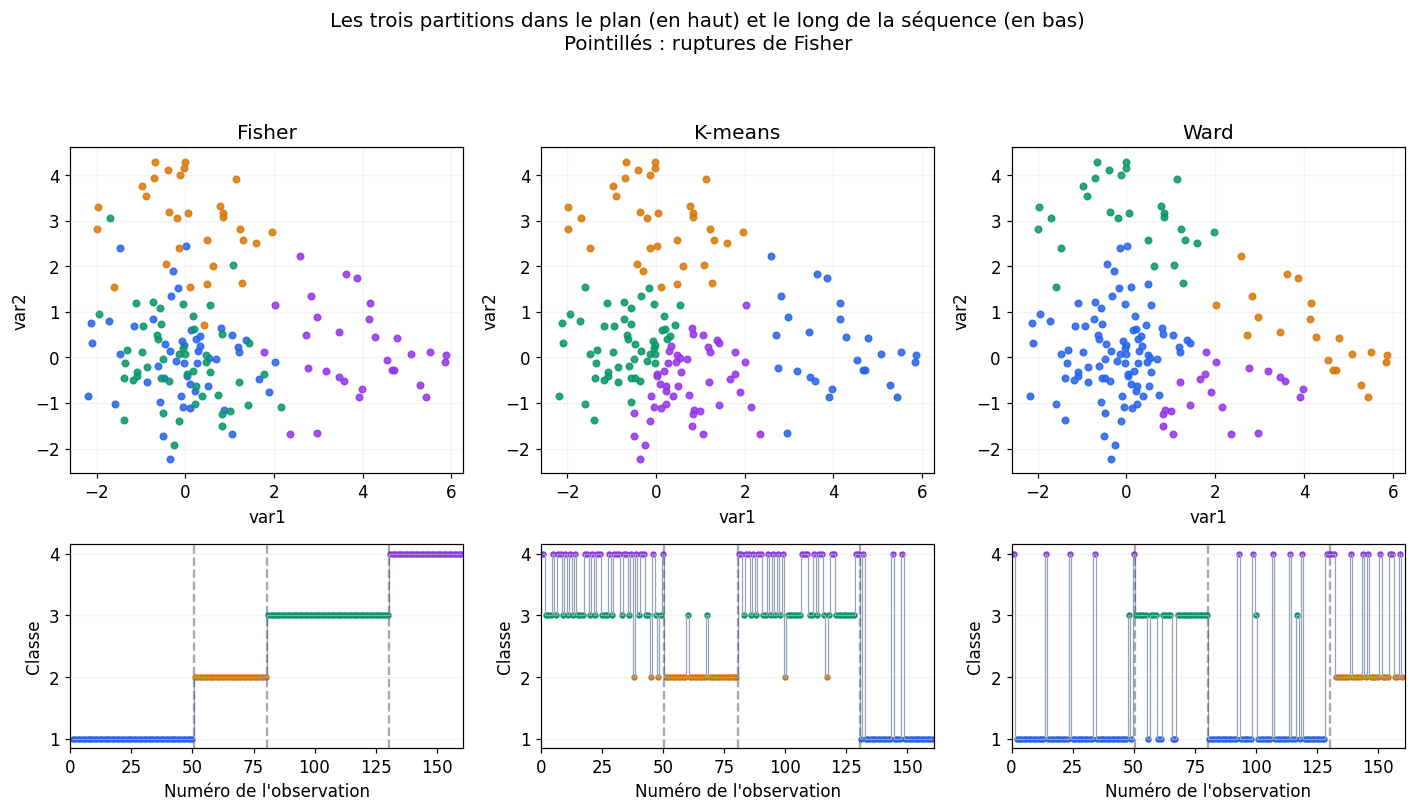

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5),
                         gridspec_kw={"height_ratios": [1.6, 1]})

for col, (nom, cluster) in enumerate(partitions.items()):
    ax = axes[0, col]
    for classe in range(1, K + 1):
        masque = cluster == classe
        ax.scatter(X[masque, 0], X[masque, 1], s=18, alpha=0.85,
                   color=couleurs[classe - 1], label=f"Classe {classe}")
    ax.set(title=nom, xlabel="var1", ylabel="var2")
    ax.grid(alpha=0.15)

    ax = axes[1, col]
    ax.step(observations, cluster, where="mid", color="#94a3b8", linewidth=0.8)
    for classe in range(1, K + 1):
        masque = cluster == classe
        ax.scatter(observations[masque], cluster[masque], s=10,
                   color=couleurs[classe - 1])
    for rupture in t:
        ax.axvline(rupture - 0.5, color="#475569", linestyle="--", alpha=0.5)
    ax.set(xlabel="Numéro de l'observation", ylabel="Classe",
           yticks=range(1, K + 1), xlim=(0, n + 1))
    ax.grid(axis="y", alpha=0.15)

fig.suptitle("Les trois partitions dans le plan (en haut) et le long de la séquence (en bas)\n"
             "Pointillés : ruptures de Fisher", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des graphiques</strong>

  <p>
    <strong>Dans le plan</strong>, K-means et Ward forment des groupes compacts,
    alors que les segments 1 et 3 de Fisher se superposent.
  </p>

  <p style="margin-bottom: 0;">
    <strong>Le long de la séquence</strong>, c’est l’inverse : Fisher donne quatre blocs
    contigus, K-means et Ward alternent entre classes. Fisher décrit les
    <strong>périodes</strong>, K-means et Ward les <strong>états</strong> visités.
  </p>

</div>

## 7. Analyse complémentaire : régimes et segments

La section précédente suggère que la séquence ne visite que **trois régimes moyens** distincts : (0, 0), (0, 3) et (4, 0), le premier étant visité deux fois. Nous vérifions cette hypothèse en :

1. fusionnant les segments 1 et 3 de Fisher, de moyennes presque identiques, pour obtenir une partition en **trois régimes** ;
2. comparant cette partition à K-means et Ward appliqués avec **K = 3**.

Cette analyse ne remplace pas la segmentation de Fisher : elle permet de comprendre pourquoi les méthodes non contraintes s’en écartent.

In [12]:
regimes_fisher = cluster_fisher.copy()
regimes_fisher[regimes_fisher == 3] = 1      # segments 1 et 3 : même régime (0, 0)

cluster_kmeans3, C_kmeans3 = clustkmeans(X, 3)
cluster_ward3, C_ward3 = clustward(X, 3)

comparaison_regimes = pd.DataFrame({
    "ARI avec les régimes de Fisher": [
        compare_partitions(regimes_fisher, cluster_kmeans3),
        compare_partitions(regimes_fisher, cluster_ward3),
        compare_partitions(regimes_fisher, cluster_kmeans),
        compare_partitions(regimes_fisher, cluster_ward),
    ],
}, index=pd.Index(["K-means (K = 3)", "Ward (K = 3)",
                   "K-means (K = 4)", "Ward (K = 4)"], name="Partition"))
display(comparaison_regimes)

print(f"Inertie des 3 régimes de Fisher : {inertie(X, regimes_fisher):,.2f}")
print(f"Inertie des 4 segments de Fisher : {C_fisher:,.2f}")
print(f"Silhouette des 3 régimes de Fisher : {silhouette(X, regimes_fisher):.4f}")

,ARI avec les régimes de Fisher
Partition,
K-means (K = 3),0.8053
Ward (K = 3),0.6335
K-means (K = 4),0.4696
Ward (K = 4),0.6414


Inertie des 3 régimes de Fisher : 300.73
Inertie des 4 segments de Fisher : 300.60
Silhouette des 3 régimes de Fisher : 0.4420


In [13]:
tableau = pd.crosstab(
    pd.Series(regimes_fisher, name="Régime de Fisher"),
    pd.Series(cluster_kmeans3, name="Groupe K-means (K = 3)"),
)
display(tableau)

Groupe K-means (K = 3),1,2,3
Régime de Fisher,,,
1,92,6,2
2,1,29,0
4,1,0,29


<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">
  <strong>Interprétation des régimes</strong>

  <p>
    Fusionner les segments 1 et 3 ne change presque pas l’inertie, mais la silhouette
    passe à environ 0,44. Avec <strong>K = 3</strong>, K-means retrouve bien ces trois
    régimes (ARI ≈ 0,81) ; Ward un peu moins (≈ 0,63).
  </p>

  <p style="margin-bottom: 0;">
    La série comporte donc <strong>quatre périodes mais trois comportements moyens</strong> :
    seul Fisher, grâce à la contrainte d’ordre, distingue les segments 1 et 3.
  </p>

</div>

## 8. Conclusion

| Méthode | Inertie (K = 4) | Silhouette | Changements de classe | Nature des groupes |
|---|---:|---:|---:|---|
| Fisher | 300,6 | 0,15 | 3 | 4 périodes contiguës |
| K-means | 202,9 | 0,37 | 75 | zone (0, 0) coupée en deux |
| Ward | 246,6 | 0,37 | 45 | groupe de points intermédiaires |

<div style="
    box-sizing: border-box;
    width: 100%;
    padding: clamp(12px, 3%, 22px);
    background-color: #f0f7ff;
    color: #243447;
    border-left: 3px solid #93c5fd;
    border-radius: 6px;
    line-height: 1.7;
    overflow-wrap: break-word;
">

  <p style="margin-top: 0;">
    La méthode du coude donne <strong>K = 4</strong>. Fisher découpe la séquence en
    <strong>1–50, 51–80, 81–130 et 131–160</strong>, de moyennes successives
    proches de (0, 0), (0, 3), (0, 0) et (4, 0).
  </p>

  <p>
    K-means et Ward obtiennent une inertie plus faible et une meilleure silhouette,
    mais leurs groupes sont dispersés dans la séquence : sans l’ordre, ils ne peuvent
    pas distinguer les segments 1 et 3, de même distribution.
  </p>

  <p style="margin-bottom: 0;">
    Pour <strong>dater les changements de régime</strong>, Fisher est adapté
    (optimum global, sans initialisation aléatoire). Pour identifier les
    <strong>états</strong> de la série, K-means avec K = 3 retrouve bien les trois régimes.
  </p>
</div>